# Benchmark: counts, clusters, monotone effects and correlated drivers

Four structures that analysts meet often, each with a method built for it.
The study asks whether mboostrs recovers the structure as well as that
specialist, and as well as the general-purpose learners:

* **counts with exposure**: claims per policy, where the time at risk enters
  as an offset and the counts are overdispersed;
* **clustered rows**: 50 groups whose levels are correlated with a
  predictor, so a model that ignores the groups attributes the group
  differences to the predictor;
* **a monotone effect** in a small, noisy sample;
* **correlated drivers**: the response depends on `x1`, and `x2` is `x1` plus
  a little noise with no effect of its own.

The competitors are the leading method for each structure: the negative
binomial GAM of the R package mgcv, glum (a penalized generalized linear
model library) and pyGAM (penalized B-spline additive models in Python) for
counts; lme4 (linear mixed models in R), mgcv's random-effect smooth and
GPBoost (tree boosting with grouped random effects) for clusters; scam
(shape-constrained additive models) for monotone effects; the lasso (glmnet)
for correlated predictors. The Explainable Boosting Machine (EBM, from
InterpretML), APLR (automatic piecewise linear regression), XGBoost, LightGBM
and CatBoost (gradient-boosted tree libraries) run on every task, each with its own offset, categorical or
monotone support.

mboostrs fits each task with `gamboost`, choosing the number of boosting
steps (`mstop`) with `tune_mstop`: 5-fold cross-validation over a grid of
step counts that doubles until the cross-validated risk stops falling or
`max_mstop` is reached, with a warning when the search ends while the risk
is still falling. `gam_refit` refits the terms a boosted model selected as
a penalized additive model whose smoothing parameters are chosen by REML
(restricted maximum likelihood), the criterion mgcv uses. Results were
measured with mboostrs 0.1.3.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | accuracy, recovery of the true effect of each predictor, and the specific failure each structure invites (ignored exposure, confounding by group, a non-monotone fit, credit given to a proxy) |
| **Observed response** | simulated: counts (negative binomial, size 2), or a continuous response with Gaussian noise |
| **Estimand** | test deviance or RMSE; the root mean squared difference between each method's partial dependence and the true centred effect; the within-group slope; monotonicity violations; the share of the effect given to the proxy |
| **Units** | deviance per row; response units; counts of grid steps |
| **Sampling unit** | one row; 2,000 (counts), 1,000 (clusters, correlated) or 300 (monotone) training rows, 4,000 test rows |
| **Dependence** | independent rows, except the clustered task, whose rows share group effects |
| **Split / resampling unit** | a fresh test sample from the same design; for clusters, also 50 new groups |
| **Tuning** | mboostrs: `tune_mstop` (5-fold cross-validation, the grid doubled until the risk turns); trees: early stopping on a 20% validation split over a size grid; mgcv, scam, lme4: REML; GPBoost: its cross-validation; EBM, APLR: defaults |
| **Uncertainty** | mean and standard error over 8 seeds |
| **Claim type** | methodological: behaviour of the methods on designs with known structure |
:::

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

bench = json.loads(Path("bench_structure.json").read_text())
rows = [{k: v for k, v in r.items() if not isinstance(v, dict)}
        for r in bench["results"] if "error" not in r]
failed = [r for r in bench["results"] if "error" in r]
structure = pl.DataFrame(rows, infer_schema_length=None)
f"{structure.height} fits over {structure['task'].n_unique()} tasks; {len(failed)} failed"

'304 fits over 4 tasks; 0 failed'

In [2]:
def summary(task, columns):
    # Mean and standard error over seeds for each method.
    part = structure.filter(pl.col("task") == task)
    aggs = []
    for column in columns:
        aggs += [pl.col(column).mean().alias(column),
                 (pl.col(column).std() / pl.len().sqrt()).alias(f"{column} se")]
    return part.group_by("method").agg(aggs)


def value(table, method, column):
    return float(table.filter(pl.col("method") == method)[column][0])

In [3]:
def dot_chart(table, column, title):
    # One point per method with a two-standard-error bar, mboostrs in colour.
    data = table.with_columns(
        (pl.col(column) - 2 * pl.col(f"{column} se")).alias("low"),
        (pl.col(column) + 2 * pl.col(f"{column} se")).alias("high"),
        pl.col("method").str.starts_with("mboostrs").alias("mboostrs"))
    base = alt.Chart(data).encode(y=alt.Y("method:N", sort="x", title=None))
    return (base.mark_rule().encode(x=alt.X("low:Q", title=title), x2="high:Q")
            + base.mark_point(filled=True, size=60).encode(
                x=f"{column}:Q",
                color=alt.Color("mboostrs:N", legend=None,
                                scale=alt.Scale(range=["#8a8a8a", "#1f5fa8"])))
            ).properties(width=420, height=22 * data.height)

## Summary of results

The table gives each method's headline measure on each of the four
structures; a dash means the method was not run on that structure.

In [4]:
from bench_tables import table as annotated

counts = summary("counts", ["deviance", "link_rmse", "signal_effect_rmse",
                            "exposure_log_ratio", "seconds"]).sort("deviance")
clustered = summary("clustered", ["rmse", "rmse_new_groups", "signal_effect_rmse",
                                  "x1_slope", "seconds"]).sort("signal_effect_rmse")
monotone = summary("monotone", ["signal_rmse", "signal_effect_rmse",
                                "monotone_violations", "seconds"]).sort("signal_effect_rmse")
correlated = summary("correlated", ["signal_rmse", "signal_effect_rmse",
                                    "proxy_share", "seconds"]).sort("proxy_share")
headline = (
    counts.select("method", pl.col("deviance").alias("c_dev"))
    .join(clustered.select("method", pl.col("x1_slope").alias("g_slope"),
                           pl.col("rmse_new_groups").alias("g_new")),
          on="method", how="full", coalesce=True)
    .join(monotone.select("method", pl.col("signal_effect_rmse").alias("m_eff"),
                          pl.col("monotone_violations").alias("m_viol")),
          on="method", how="full", coalesce=True)
    .join(correlated.select("method", pl.col("proxy_share").alias("p_share")),
          on="method", how="full", coalesce=True)
    .sort("method"))

In [5]:
annotated(
    headline,
    title="Four structures: each method's headline measure",
    subtitle="Mean over 8 seeds per structure",
    spanners={"Counts": ["c_dev"], "Clusters": ["g_slope", "g_new"],
              "Monotone": ["m_eff", "m_viol"], "Correlated": ["p_share"]},
    labels={"c_dev": "deviance ↓", "g_slope": "x1 slope", "g_new": "new-group RMSE ↓",
            "m_eff": "effect error ↓", "m_viol": "violations ↓", "p_share": "proxy share ↓"},
    better={"c_dev": "min", "g_slope": 0.5, "g_new": "min", "m_eff": "min", "m_viol": "min",
            "p_share": "min"},
    formats={"m_viol": 1},
    notes=["Counts: mean test deviance per row of negative binomial counts with an exposure "
           "offset. Clusters: the within-group slope of x1 (true value 0.5; ignoring the "
           "groups inflates it) and the RMSE on rows from 50 groups the fit never saw. "
           "Monotone: RMSE of the partial dependences against the true effects, and the "
           "decreases in the 25-point curve of the increasing effect. Correlated: share of "
           "the effect given to a noisy copy of the driver.",
           "Bold: best in the column (for the slope, closest to 0.5). Each section below "
           "gives the full table with standard errors. Source: bench_structure.json."])

GT(_tbl_data=shape: (17, 7)
┌────────────────────────┬──────────┬──────────┬──────────┬──────────┬────────┬──────────┐
│ method                 ┆ c_dev    ┆ g_slope  ┆ g_new    ┆ m_eff    ┆ m_viol ┆ p_share  │
│ ---                    ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---    ┆ ---      │
│ str                    ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64    ┆ f64      │
╞════════════════════════╪══════════╪══════════╪══════════╪══════════╪════════╪══════════╡
│ APLR                   ┆ 1.105523 ┆ null     ┆ null     ┆ 0.153697 ┆ 0.0    ┆ 0.070599 │
│ CatBoost               ┆ 1.113072 ┆ 0.676818 ┆ 0.997874 ┆ 0.115597 ┆ 0.0    ┆ 0.195438 │
│ EBM                    ┆ 1.102479 ┆ 0.775922 ┆ 1.2568   ┆ 0.104003 ┆ 3.25   ┆ 0.229707 │
│ GPBoost                ┆ null     ┆ 0.392975 ┆ 1.206293 ┆ null     ┆ null   ┆ null     │
│ LightGBM               ┆ 1.103169 ┆ 0.501448 ┆ 1.141235 ┆ 0.140502 ┆ 0.0    ┆ 0.068143 │
│ …                      ┆ …        ┆ …        ┆ …        ┆ …        ┆ …      ┆ …        │
│ mboostrs bmono         ┆ null     ┆ null     ┆ null     ┆ 0.103574 ┆ 0.0    ┆ null     │
│ mboostrs without group ┆ null     ┆ 1.311933 ┆ 0.798325 ┆ null     ┆ null   ┆ null     │
│ mgcv                   ┆ 1.102191 ┆ 0.527858 ┆ 1.097719 ┆ 0.094229 ┆ 2.625  ┆ 0.021816 │
│ pyGAM                  ┆ 1.139635 ┆ null     ┆ null     ┆ null     ┆ null   ┆ null     │
│ scam                   ┆ null     ┆ null     ┆ null     ┆ 0.089134 ┆ 0.0    ┆ null     │
└────────────────────────┴──────────┴──────────┴──────────┴──────────┴────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10aee90d0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='c_dev', type=<ColInfoTypeEnum.default: 1>, column_label='deviance ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='g_slope', type=<ColInfoTypeEnum.default: 1>, column_label='x1 slope', column_align='right', column_width=None, stub_level=None), ColInfo(var='g_new', type=<ColInfoTypeEnum.default: 1>, column_label='new-group RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='m_eff', type=<ColInfoTypeEnum.default: 1>, column_label='effect error ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='m_viol', type=<ColInfoTypeEnum.default: 1>, column_label='violations ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='p_share', type=<ColInfoTypeEnum.default: 1>, column_label='proxy share ↓', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x109105760>, _spanners=Spanners([SpannerInfo(spanner_id='Counts', spanner_level=0, spanner_label='Counts', spanner_units=None, spanner_pattern=None, vars=['c_dev'], built=None), SpannerInfo(spanner_id='Clusters', spanner_level=0, spanner_label='Clusters', spanner_units=None, spanner_pattern=None, vars=['g_slope', 'g_new'], built=None), SpannerInfo(spanner_id='Monotone', spanner_level=0, spanner_label='Monotone', spanner_units=None, spanner_pattern=None, vars=['m_eff', 'm_viol'], built=None), SpannerInfo(spanner_id='Correlated', spanner_level=0, spanner_label='Correlated', spanner_units=None, spanner_pattern=None, vars=['p_share'], built=None)]), _heading=Heading(title="Four structures: each method's headline measure", subtitle='Mean over 8 seeds per structure', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10adf5e80>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x109105a30>, _source_notes=['Counts: mean test deviance per row of negative binomial counts with an exposure offset. Clusters: the within-group slope of x1 (true value 0.5; ignoring the groups inflates it) and the RMSE on rows from 50 groups the fit never saw. Monotone: RMSE of the partial dependences against the true effects, and the decreases in t

## Counts with an exposure offset

Each row is a policy with exposure $e$ between 0.1 and 2 years; the count is
negative binomial with mean $e\,\exp\{-1 + 0.6\sin 2x_1 + 0.4x_2 +
0.5[x_3 > 0]\}$ and size 2 (variance $\mu + \mu^2/2$). Three of the six
predictors are noise. Every method gets $\log e$ as an offset in the way its
library supports (`offset=` in mboostrs, `offset(log(e))` in mgcv, a base
margin or initial score in the tree libraries and EBM, `exposure=` in pyGAM;
APLR has no offset and is fitted to the rate $y/e$ with weight $e$, which has
the same Poisson likelihood). mboostrs uses `NBinomial`, which re-estimates the
dispersion at each boosting step; `nuisance()` reports the dispersion at the
model's step count. Cross-validation (`cvrisk`, and so `tune_mstop`) starts
every fold from the offset $\log e$, as R mboost's `cvrisk` does; the two
agree to 1e-6 on the cross-validated risk.

In [6]:
counts = summary("counts", ["deviance", "link_rmse", "signal_effect_rmse",
                            "exposure_log_ratio", "seconds"]).sort("deviance")
display(annotated(
    counts.select("method", "deviance", "deviance se", "link_rmse", "signal_effect_rmse",
                  "exposure_log_ratio", "seconds"),
    title="Counts with an exposure offset",
    subtitle="Negative binomial counts, 6 predictors (3 noise); mean over 8 seeds",
    labels={"deviance": "deviance ↓", "deviance se": "se", "link_rmse": "log-mean RMSE ↓",
            "signal_effect_rmse": "effect error ↓", "exposure_log_ratio": "exposure effect",
            "seconds": "s"},
    better={"deviance": "min", "link_rmse": "min", "signal_effect_rmse": "min",
            "exposure_log_ratio": 0.693},
    formats={"seconds": 1},
    notes=["deviance: mean Poisson deviance per test row (4,000 rows). log-mean RMSE: root "
           "mean squared error of the predicted log mean against the true one. effect "
           "error: RMSE of each true predictor's partial dependence on the log scale "
           "against its true centred effect, averaged over the three. exposure effect: "
           "the change in the predicted log mean when the exposure doubles; an offset "
           "implies log 2 = 0.693. se: standard error of the deviance over seeds. s: mean "
           "seconds per fit including tuning. Bold: best in the column (for the exposure "
           "effect, closest to 0.693)."]))

GT(_tbl_data=shape: (10, 7)
┌────────────┬──────────┬─────────────┬───────────┬──────────────────┬─────────────────┬───────────┐
│ method     ┆ deviance ┆ deviance se ┆ link_rmse ┆ signal_effect_rm ┆ exposure_log_ra ┆ seconds   │
│ ---        ┆ ---      ┆ ---         ┆ ---       ┆ se               ┆ tio             ┆ ---       │
│ str        ┆ f64      ┆ f64         ┆ f64       ┆ ---              ┆ ---             ┆ f64       │
│            ┆          ┆             ┆           ┆ f64              ┆ f64             ┆           │
╞════════════╪══════════╪═════════════╪═══════════╪══════════════════╪═════════════════╪═══════════╡
│ mboostrs   ┆ 1.10103  ┆ 0.009936    ┆ 0.17104   ┆ 0.081298         ┆ 0.693147        ┆ 1.312546  │
│ mgcv       ┆ 1.102191 ┆ 0.009983    ┆ 0.171604  ┆ 0.0722           ┆ 0.693147        ┆ 9.661263  │
│ mboostrs + ┆ 1.102262 ┆ 0.010019    ┆ 0.171283  ┆ 0.072204         ┆ 0.693147        ┆ 10.201265 │
│ REML refit ┆          ┆             ┆           ┆                  ┆                 ┆           │
│ EBM        ┆ 1.102479 ┆ 0.011274    ┆ 0.186619  ┆ 0.077232         ┆ 0.693147        ┆ 20.292939 │
│ LightGBM   ┆ 1.103169 ┆ 0.010271    ┆ 0.196797  ┆ 0.091128         ┆ 0.693147        ┆ 1.879714  │
│ XGBoost    ┆ 1.105059 ┆ 0.011508    ┆ 0.199273  ┆ 0.092307         ┆ 0.693147        ┆ 1.886981  │
│ APLR       ┆ 1.105523 ┆ 0.01033     ┆ 0.192412  ┆ 0.092546         ┆ 0.693147        ┆ 6.609839  │
│ glum       ┆ 1.106108 ┆ 0.011562    ┆ 0.212812  ┆ 0.087053         ┆ 0.693147        ┆ 2.4513    │
│ CatBoost   ┆ 1.113072 ┆ 0.010541    ┆ 0.255052  ┆ 0.107033         ┆ 0.693147        ┆ 2.400368  │
│ pyGAM      ┆ 1.139635 ┆ 0.019488    ┆ 0.309457  ┆ 0.114092         ┆ 0.693147        ┆ 2.066171  │
└────────────┴──────────┴─────────────┴───────────┴──────────────────┴─────────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10b2882f0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='deviance', type=<ColInfoTypeEnum.default: 1>, column_label='deviance ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='deviance se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None, stub_level=None), ColInfo(var='link_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='log-mean RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='effect error ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='exposure_log_ratio', type=<ColInfoTypeEnum.default: 1>, column_label='exposure effect', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10943b2f0>, _spanners=Spanners([]), _heading=Heading(title='Counts with an exposure offset', subtitle='Negative binomial counts, 6 predictors (3 noise); mean over 8 seeds', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b2893d0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b28ab10>, _source_notes=["deviance: mean Poisson deviance per test row (4,000 rows). log-mean RMSE: root mean squared error of the predicted log mean against the true one. effect error: RMSE of each true predictor's partial dependence on the log scale against its true centred effect, averaged over the three. exposure effect: the change in the predicted log mean when the exposure doubles; an offset implies log 2 = 0.693. se: standard error of the deviance over seeds. s: mean seconds per fit including tuning. Bold: best in the column (for the exposure effect, closest to 0.693)."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=

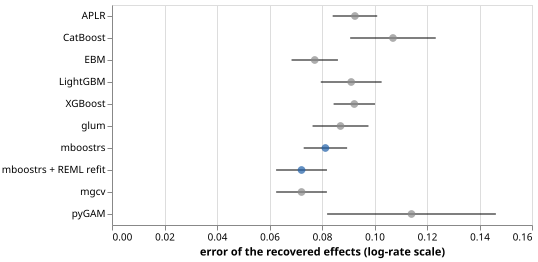

In [7]:
display(dot_chart(counts, "signal_effect_rmse",
                  "error of the recovered effects (log-rate scale)"))

All methods treat the exposure correctly: doubling it adds
{eval}`round(value(counts, "mboostrs", "exposure_log_ratio"), 3)` to the log
mean for every one of them, the $\log 2$ an offset implies. The deviance is
the mean Poisson deviance per test row (lower is better). mboostrs has the
lowest test deviance, {eval}`round(value(counts, "mboostrs", "deviance"), 3)`
(mgcv {eval}`round(value(counts, "mgcv", "deviance"), 3)`), and its linear
predictor is as close to the truth as mgcv's (RMSE
{eval}`round(value(counts, "mboostrs", "link_rmse"), 3)` against
{eval}`round(value(counts, "mgcv", "link_rmse"), 3)`). On the recovered
effects mgcv is ahead ({eval}`round(value(counts, "mgcv", "signal_effect_rmse"), 3)`
against {eval}`round(value(counts, "mboostrs", "signal_effect_rmse"), 3)`):
early stopping shrinks the boosted curves. `gam_refit`, which refits the
selected terms by REML and estimates the dispersion by the same criterion
(it accepts `offset=` for the exposure), gives
{eval}`round(value(counts, "mboostrs + REML refit", "signal_effect_rmse"), 3)`.
The tree libraries are faster and less accurate on the effects, and pyGAM
is the least accurate
({eval}`round(value(counts, "pyGAM", "signal_effect_rmse"), 3)`).

## Clustered rows

Fifty groups with 20 rows each; the group effect $b_g$ is normal with
standard deviation 1, and $x_1 = 0.8\,b_g + \varepsilon$, so a group's level
and its values of $x_1$ move together. The response is
$0.5x_1 + \sin 2x_2 + b_g + \varepsilon$. The within-group effect of $x_1$
is 0.5; a model without the group term also credits $x_1$ with the
between-group association and estimates a much steeper slope. Test rows come
from the same groups and from 50 new ones. mboostrs uses `brandom(g)`, a
learner with one coefficient per group and a ridge penalty on them, which
is the boosting form of a random intercept; with 50 levels at its default
`df=4` it needs about 4,000 boosting steps, which `tune_mstop`'s doubling
grid reaches. lme4 uses a random intercept with natural-spline terms, mgcv `s(g, bs = "re")`,
GPBoost a grouped random effect, and EBM and the tree libraries the group as a
categorical feature. For new groups, each mixed model predicts the average
group (`unseen_levels="zero_effect"` in mboostrs, accepted by both the boosted
fit and `gam_refit`).

In [8]:
clustered = summary("clustered", ["rmse", "rmse_new_groups", "signal_effect_rmse",
                                  "x1_slope", "seconds"]).sort("signal_effect_rmse")
display(annotated(
    clustered.select("method", "rmse", "rmse_new_groups", "signal_effect_rmse",
                     "x1_slope", "x1_slope se", "seconds"),
    title="Clustered rows: 50 groups whose level is correlated with x1",
    subtitle="Mean over 8 seeds; the true within-group slope of x1 is 0.5",
    spanners={"Test RMSE ↓": ["rmse", "rmse_new_groups"]},
    labels={"rmse": "same groups", "rmse_new_groups": "new groups",
            "signal_effect_rmse": "effect error ↓", "x1_slope": "x1 slope",
            "x1_slope se": "se", "seconds": "s"},
    better={"rmse": "min", "rmse_new_groups": "min", "signal_effect_rmse": "min",
            "x1_slope": 0.5},
    formats={"seconds": 1},
    notes=["Test RMSE: root mean squared prediction error, in response units, on rows from "
           "the training groups and from 50 new groups. effect error: RMSE of the partial "
           "dependences of x1 and x2 against their true centred effects. x1 slope: the "
           "within-group slope of x1 read from the fitted model, with its standard error "
           "over seeds; a model that ignores the groups credits x1 with the group effect "
           "and estimates a steeper slope. s: mean seconds per fit including tuning. Bold: "
           "best in the column (for the slope, closest to 0.5)."]))

GT(_tbl_data=shape: (10, 7)
┌────────────────┬──────────┬────────────────┬────────────────┬──────────┬─────────────┬───────────┐
│ method         ┆ rmse     ┆ rmse_new_group ┆ signal_effect_ ┆ x1_slope ┆ x1_slope se ┆ seconds   │
│ ---            ┆ ---      ┆ s              ┆ rmse           ┆ ---      ┆ ---         ┆ ---       │
│ str            ┆ f64      ┆ ---            ┆ ---            ┆ f64      ┆ f64         ┆ f64       │
│                ┆          ┆ f64            ┆ f64            ┆          ┆             ┆           │
╞════════════════╪══════════╪════════════════╪════════════════╪══════════╪═════════════╪═══════════╡
│ mgcv           ┆ 0.511693 ┆ 1.097719       ┆ 0.036899       ┆ 0.527858 ┆ 0.013737    ┆ 3.972724  │
│ mboostrs +     ┆ 0.511751 ┆ 1.097692       ┆ 0.037274       ┆ 0.528261 ┆ 0.013716    ┆ 2.908476  │
│ REML refit     ┆          ┆                ┆                ┆          ┆             ┆           │
│ lme4           ┆ 0.511544 ┆ 1.099467       ┆ 0.039287       ┆ 0.52832  ┆ 0.016177    ┆ 1.71376   │
│ mboostrs       ┆ 0.514066 ┆ 1.099253       ┆ 0.047406       ┆ 0.527331 ┆ 0.015081    ┆ 2.740916  │
│ XGBoost        ┆ 0.527532 ┆ 2.434019       ┆ 0.085945       ┆ 0.482558 ┆ 0.015207    ┆ 1.712965  │
│ LightGBM       ┆ 0.528018 ┆ 1.141235       ┆ 0.088645       ┆ 0.501448 ┆ 0.0189      ┆ 1.866682  │
│ GPBoost        ┆ 0.533299 ┆ 1.206293       ┆ 0.111892       ┆ 0.392975 ┆ 0.017061    ┆ 2.035323  │
│ CatBoost       ┆ 0.550654 ┆ 0.997874       ┆ 0.13832        ┆ 0.676818 ┆ 0.037619    ┆ 2.371235  │
│ EBM            ┆ 0.575023 ┆ 1.2568         ┆ 0.192057       ┆ 0.775922 ┆ 0.045103    ┆ 28.673873 │
│ mboostrs       ┆ 0.777073 ┆ 0.798325       ┆ 0.426508       ┆ 1.311933 ┆ 0.01403     ┆ 0.514566  │
│ without group  ┆          ┆                ┆                ┆          ┆             ┆           │
└────────────────┴──────────┴────────────────┴────────────────┴──────────┴─────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10b19ff80>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='rmse', type=<ColInfoTypeEnum.default: 1>, column_label='same groups', column_align='right', column_width=None, stub_level=None), ColInfo(var='rmse_new_groups', type=<ColInfoTypeEnum.default: 1>, column_label='new groups', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='effect error ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='x1_slope', type=<ColInfoTypeEnum.default: 1>, column_label='x1 slope', column_align='right', column_width=None, stub_level=None), ColInfo(var='x1_slope se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b2891f0>, _spanners=Spanners([SpannerInfo(spanner_id='Test RMSE ↓', spanner_level=0, spanner_label='Test RMSE ↓', spanner_units=None, spanner_pattern=None, vars=['rmse', 'rmse_new_groups'], built=None)]), _heading=Heading(title='Clustered rows: 50 groups whose level is correlated with x1', subtitle='Mean over 8 seeds; the true within-group slope of x1 is 0.5', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b2ebcb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b31d850>, _source_notes=['Test RMSE: root mean squared prediction error, in response units, on rows from the training groups and from 50 new groups. effect error: RMSE of the partial dependences of x1 and x2 against their true centred effects. x1 slope: the within-group slope of x1 read from the fitted model, with its standard error over seeds; a model that ignores the groups cr

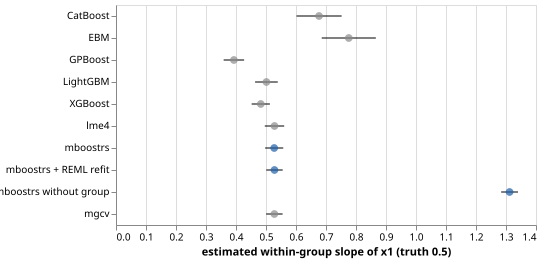

In [9]:
display(dot_chart(clustered, "x1_slope", "estimated within-group slope of x1 (truth 0.5)"))

The models with a group term recover the within-group slope: mboostrs
{eval}`round(value(clustered, "mboostrs", "x1_slope"), 3)`, lme4
{eval}`round(value(clustered, "lme4", "x1_slope"), 3)`, mgcv
{eval}`round(value(clustered, "mgcv", "x1_slope"), 3)`; without it mboostrs
estimates {eval}`round(value(clustered, "mboostrs without group", "x1_slope"), 2)`.
EBM ({eval}`round(value(clustered, "EBM", "x1_slope"), 2)`) and CatBoost
({eval}`round(value(clustered, "CatBoost", "x1_slope"), 2)`) share the group
effect between the categorical feature and $x_1$ and fall between the two.
`gam_refit` turns the boosted model into the REML fit that mgcv computes: its
effect error, {eval}`round(value(clustered, "mboostrs + REML refit", "signal_effect_rmse"), 3)`,
is within 0.001 of mgcv's
({eval}`round(value(clustered, "mgcv", "signal_effect_rmse"), 3)`).

The model without the group term predicts new groups best
({eval}`round(value(clustered, "mboostrs without group", "rmse_new_groups"), 3)`
against {eval}`round(value(clustered, "mboostrs", "rmse_new_groups"), 3)`), because
$x_1$ carries information about the unknown group level. That is the choice
the analysis has to make: the random-effect model gives the effect of $x_1$
within a group, the pooled model the best forecast for a group seen for the
first time. XGBoost predicts new groups worst
({eval}`round(value(clustered, "XGBoost", "rmse_new_groups"), 3)`), well behind
LightGBM and CatBoost, which also treat the group as a categorical feature.

## A monotone effect

Three hundred rows, $y = 2/(1 + e^{-6x_1}) + 0.5x_2^2 + \varepsilon$ with
noise standard deviation 0.8, and $x_3$ irrelevant. The effect of $x_1$ is
known to increase. `bmono(x1, constraint='increasing')` in mboostrs (a P-spline whose
coefficients are constrained to increase, so the fitted curve cannot
decrease), scam's
`s(x1, bs = "mpi")`, the tree libraries' monotone constraints, APLR's
monotone constraints and EBM's `monotonize` enforce it; mgcv and mboostrs
with `bbs` (the unconstrained P-spline) do not. A violation is a decrease between consecutive points of
the 25-point partial-dependence grid.

In [10]:
monotone = summary("monotone", ["signal_rmse", "signal_effect_rmse",
                                "monotone_violations", "seconds"]).sort("signal_effect_rmse")
display(annotated(
    monotone.select("method", "signal_rmse", "signal_effect_rmse", "signal_effect_rmse se",
                    "monotone_violations", "seconds"),
    title="A monotone effect in 300 noisy rows",
    subtitle="Mean over 8 seeds; the effect of x1 is known to increase",
    labels={"signal_rmse": "signal RMSE ↓", "signal_effect_rmse": "effect error ↓",
            "signal_effect_rmse se": "se", "monotone_violations": "violations ↓",
            "seconds": "s"},
    better={"signal_rmse": "min", "signal_effect_rmse": "min", "monotone_violations": "min"},
    formats={"monotone_violations": 1, "seconds": 1},
    notes=["signal RMSE: root mean squared difference between the predicted and the true "
           "mean on the test rows. effect error: RMSE of the partial dependences against "
           "the true centred effects, with its standard error over seeds. violations: "
           "decreases between consecutive points of the 25-point partial-dependence grid "
           "of x1 (0 for a monotone curve). s: mean seconds per fit including tuning. "
           "Bold: best in the column."]))

GT(_tbl_data=shape: (9, 6)
┌────────────────┬─────────────┬──────────────────┬──────────────────┬──────────────────┬──────────┐
│ method         ┆ signal_rmse ┆ signal_effect_rm ┆ signal_effect_rm ┆ monotone_violati ┆ seconds  │
│ ---            ┆ ---         ┆ se               ┆ se se            ┆ ons              ┆ ---      │
│ str            ┆ f64         ┆ ---              ┆ ---              ┆ ---              ┆ f64      │
│                ┆             ┆ f64              ┆ f64              ┆ f64              ┆          │
╞════════════════╪═════════════╪══════════════════╪══════════════════╪══════════════════╪══════════╡
│ scam           ┆ 0.146617    ┆ 0.089134         ┆ 0.008361         ┆ 0.0              ┆ 1.671923 │
│ mgcv           ┆ 0.154054    ┆ 0.094229         ┆ 0.009362         ┆ 2.625            ┆ 1.656684 │
│ mboostrs       ┆ 0.158403    ┆ 0.098385         ┆ 0.010772         ┆ 1.75             ┆ 0.264112 │
│ mboostrs bmono ┆ 0.165565    ┆ 0.103574         ┆ 0.009178         ┆ 0.0              ┆ 0.366354 │
│ EBM            ┆ 0.193999    ┆ 0.104003         ┆ 0.007682         ┆ 3.25             ┆ 5.223984 │
│ CatBoost       ┆ 0.238863    ┆ 0.115597         ┆ 0.01462          ┆ 0.0              ┆ 2.563062 │
│ XGBoost        ┆ 0.272714    ┆ 0.131952         ┆ 0.012993         ┆ 0.0              ┆ 1.435303 │
│ LightGBM       ┆ 0.27358     ┆ 0.140502         ┆ 0.016122         ┆ 0.0              ┆ 1.359925 │
│ APLR           ┆ 0.258377    ┆ 0.153697         ┆ 0.006811         ┆ 0.0              ┆ 1.275912 │
└────────────────┴─────────────┴──────────────────┴──────────────────┴──────────────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10aabf980>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='signal_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='signal RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='effect error ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_effect_rmse se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None, stub_level=None), ColInfo(var='monotone_violations', type=<ColInfoTypeEnum.default: 1>, column_label='violations ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10b01da00>, _spanners=Spanners([]), _heading=Heading(title='A monotone effect in 300 noisy rows', subtitle='Mean over 8 seeds; the effect of x1 is known to increase', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b31e780>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b31c260>, _source_notes=['signal RMSE: root mean squared difference between the predicted and the true mean on the test rows. effect error: RMSE of the partial dependences against the true centred effects, with its standard error over seeds. violations: decreases between consecutive points of the 25-point partial-dependence grid of x1 (0 for a monotone curve). s: mean seconds per fit including tuning. Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31F1A0>, mask=None), grpname=None, colname='signal_rmse', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31F1A0>, mask=None), grpname=None, colname='signal_rmse', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31F1A0>, mas

Every constrained method returns a monotone curve; mgcv and mboostrs with
`bbs` have {eval}`round(value(monotone, "mgcv", "monotone_violations"), 1)` and
{eval}`round(value(monotone, "mboostrs", "monotone_violations"), 1)` decreasing
grid steps on average. scam has the smallest effect error
({eval}`round(value(monotone, "scam", "signal_effect_rmse"), 3)`); `bmono`
({eval}`round(value(monotone, "mboostrs bmono", "signal_effect_rmse"), 3)`) is
behind it and slightly behind unconstrained `bbs`
({eval}`round(value(monotone, "mboostrs", "signal_effect_rmse"), 3)`), because
`bmono`'s default of 4 degrees of freedom and early stopping flatten the
steep middle of the curve. Over six seeds, the effect error of `bmono` was 0.135 with its default of 4 degrees of freedom and 0.123 with `df=6`. APLR and the tree libraries' constrained step functions are
the least accurate on this smooth curve.

## Correlated drivers

A thousand rows with eight standard normal predictors, $x_2 = x_1 + $ noise
with standard deviation 0.3 (correlation about 0.96), and
$y = \sin 1.5x_1 + 0.6x_3 + \varepsilon$. The proxy share is the spread of the
partial dependence on $x_2$ divided by the sum of the spreads on $x_1$ and on
$x_2$, $s_2/(s_1 + s_2)$: 0 when a method gives $x_2$ nothing, 0.5 when it
splits the effect evenly (lower is better).

In [11]:
correlated = summary("correlated", ["signal_rmse", "signal_effect_rmse",
                                    "proxy_share", "seconds"]).sort("proxy_share")
display(annotated(
    correlated.select("method", "signal_rmse", "signal_effect_rmse", "proxy_share",
                      "proxy_share se", "seconds"),
    title="Correlated drivers: x2 is a noisy copy of the driver x1",
    subtitle="Mean over 8 seeds; 1,000 rows, correlation of x1 and x2 about 0.96",
    labels={"signal_rmse": "signal RMSE ↓", "signal_effect_rmse": "effect error ↓",
            "proxy_share": "proxy share ↓", "proxy_share se": "se", "seconds": "s"},
    better={"signal_rmse": "min", "signal_effect_rmse": "min", "proxy_share": "min"},
    formats={"seconds": 1},
    notes=["proxy share: the spread of the partial dependence on x2 divided by the spread "
           "on x1 plus that on x2; 0 when the proxy gets nothing, 0.5 when the effect is "
           "split evenly. signal RMSE and effect error as in the monotone table. s: mean "
           "seconds per fit including tuning. Bold: best in the column."]))

GT(_tbl_data=shape: (9, 6)
┌──────────────┬─────────────┬────────────────────┬─────────────┬────────────────┬───────────┐
│ method       ┆ signal_rmse ┆ signal_effect_rmse ┆ proxy_share ┆ proxy_share se ┆ seconds   │
│ ---          ┆ ---         ┆ ---                ┆ ---         ┆ ---            ┆ ---       │
│ str          ┆ f64         ┆ f64                ┆ f64         ┆ f64            ┆ f64       │
╞══════════════╪═════════════╪════════════════════╪═════════════╪════════════════╪═══════════╡
│ mboostrs +   ┆ 0.090938    ┆ 0.03463            ┆ 4.6207e-18  ┆ 3.0296e-18     ┆ 0.391249  │
│ deselection  ┆             ┆                    ┆             ┆                ┆           │
│ mboostrs     ┆ 0.100968    ┆ 0.03941            ┆ 0.007969    ┆ 0.004353       ┆ 0.369829  │
│ mgcv         ┆ 0.093197    ┆ 0.042981           ┆ 0.021816    ┆ 0.015009       ┆ 13.534145 │
│ glmnet lasso ┆ 0.511535    ┆ 0.210901           ┆ 0.031334    ┆ 0.015487       ┆ 1.709391  │
│ LightGBM     ┆ 0.193992    ┆ 0.11174            ┆ 0.068143    ┆ 0.01508        ┆ 1.750867  │
│ XGBoost      ┆ 0.189971    ┆ 0.107485           ┆ 0.069439    ┆ 0.012801       ┆ 1.840999  │
│ APLR         ┆ 0.169314    ┆ 0.090477           ┆ 0.070599    ┆ 0.014714       ┆ 4.838957  │
│ CatBoost     ┆ 0.210742    ┆ 0.130117           ┆ 0.195438    ┆ 0.01207        ┆ 2.615281  │
│ EBM          ┆ 0.172591    ┆ 0.120234           ┆ 0.229707    ┆ 0.009638       ┆ 30.107422 │
└──────────────┴─────────────┴────────────────────┴─────────────┴────────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10b31e300>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='signal_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='signal RMSE ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='signal_effect_rmse', type=<ColInfoTypeEnum.default: 1>, column_label='effect error ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='proxy_share', type=<ColInfoTypeEnum.default: 1>, column_label='proxy share ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='proxy_share se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None, stub_level=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x108a24980>, _spanners=Spanners([]), _heading=Heading(title='Correlated drivers: x2 is a noisy copy of the driver x1', subtitle='Mean over 8 seeds; 1,000 rows, correlation of x1 and x2 about 0.96', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b31d6a0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b31e480>, _source_notes=['proxy share: the spread of the partial dependence on x2 divided by the spread on x1 plus that on x2; 0 when the proxy gets nothing, 0.5 when the effect is split evenly. signal RMSE and effect error as in the monotone table. s: mean seconds per fit including tuning. Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31C9E0>, mask=None), grpname=None, colname='signal_rmse', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31C9E0>, mask=None), grpname=None, colname='signal_rmse', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B31C9E0>, mask=None), grpname=None, colname='signal_effect_rmse', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.star

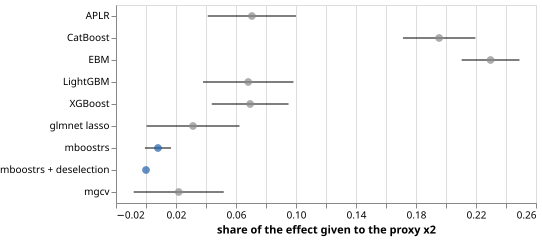

In [12]:
display(dot_chart(correlated, "proxy_share", "share of the effect given to the proxy x2"))

Component-wise boosting chooses one learner (one candidate term) per step, and the true driver
fits each step's residual slightly better than its noisy copy, so it wins
almost every step: mboostrs gives the proxy
{eval}`round(100 * value(correlated, "mboostrs", "proxy_share"), 1)`% of the
effect, and none after deselection (`mb.deselect`, which removes the
learners whose share of the total risk reduction is below 1% and refits). mgcv with `select=TRUE` gives it
{eval}`round(100 * value(correlated, "mgcv", "proxy_share"), 1)`%, the
gradient-boosted trees about
{eval}`round(100 * value(correlated, "LightGBM", "proxy_share"))`%, EBM
{eval}`round(100 * value(correlated, "EBM", "proxy_share"))`% and CatBoost
{eval}`round(100 * value(correlated, "CatBoost", "proxy_share"))`%. EBM boosts
the features in turn (round robin), so the proxy is fitted to whatever residual
is left when its turn comes. The lasso keeps the proxy out but, being linear,
misses the sine ({eval}`round(value(correlated, "glmnet lasso", "signal_effect_rmse"), 3)`).

## Summary

| Structure | mboostrs | Leader | Remaining gap |
|---|---|---|---|
| Counts with exposure | lowest test deviance; linear predictor as accurate as mgcv | mboostrs, mgcv | effect curves shrunk by early stopping; `gam_refit` removes most of it |
| Clusters | within-group slope as lme4 and mgcv; REML refit matches mgcv | lme4, mgcv, mboostrs | none on these measures |
| Monotone effect | monotone, fast | scam | shape-constrained curves are flatter than scam's REML fit |
| Correlated drivers | no credit to the proxy after deselection | mboostrs | none |

## Limitations

The designs are small and simulated, with one structure at a time; real data
mix them. Each competitor runs with the documented defaults or a small tuning
grid, not an expert's configuration. The partial-dependence measure averages
over the observed values of the other predictors, which is the effect a
reader of each library's plots would see, but for the tree methods it mixes
main effects with interactions.

## Reproduction

The page reads `bench_structure.json`, which stores one record per task,
method and seed (8 seeds, 4,000 test rows, a 25-point partial-dependence
grid), the tuning protocol and the library versions.